<a href="https://colab.research.google.com/github/vishwakumar1311/MiniGrad/blob/main/NeuralNetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# imports and seed
%pip install -q graphviz torch

import math
import random

import torch
from graphviz import Digraph

random.seed(42)

In [2]:
# autograd engine: each Value stores its data, gradient and a local backward step
class Value:
    def __init__(self, data, children=(), op="", label=""):
        self.data = data
        self.children = set(children)
        self.grad = 0.0
        self.op = op
        self.label = label
        self._backward = lambda: None

    def __repr__(self):
        return f"Value({self.label} {self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, children=(self, other), op="+")
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, children=(self, other), op="*")
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only int/float powers are supported"
        out = Value(self.data ** other, children=(self,), op=f"**{other}")
        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        out = Value(math.tanh(self.data), children=(self,), op="tanh")
        def _backward():
            self.grad += (1 - out.data ** 2) * out.grad
        out._backward = _backward
        return out

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __truediv__(self, other):
        return self * other ** -1

    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __rsub__(self, other):
        return (-self) + other

    def __rtruediv__(self, other):
        return other * self ** -1

    def backward(self):
        topo, visited = [], set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v.children:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [3]:
# draw the computation graph with Graphviz
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.children:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})  # left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape="record")
        if n.op:
            dot.node(name=uid + n.op, label=n.op)
            dot.edge(uid + n.op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)
    return dot

Value(z 0.7778880665771849)


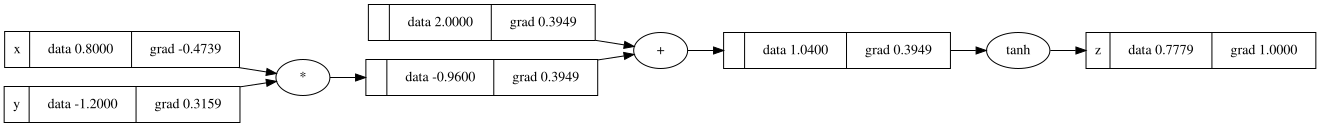

In [4]:
# example forward and backward pass
x = Value(0.8, label="x")
y = Value(-1.2, label="y")
z = (x * y + 2.0).tanh()
z.label = "z"
z.backward()
print(z)
draw_dot(z)

In [5]:
# check minigrad's gradients against PyTorch
def expression(a, b, c, tanh):
    return tanh(((a * b + c) ** 2 / (1 + a)) - b * (2 - c))

vals = {"a": 0.7, "b": -1.3, "c": 2.1}

# MiniGrad
mg = {k: Value(v, label=k) for k, v in vals.items()}
mg_out = expression(mg["a"], mg["b"], mg["c"], lambda v: v.tanh())
mg_out.backward()

# PyTorch
pt = {k: torch.tensor(v, dtype=torch.float64, requires_grad=True) for k, v in vals.items()}
pt_out = expression(pt["a"], pt["b"], pt["c"], torch.tanh)
pt_out.backward()

print(f"output     minigrad={mg_out.data:.12f}  torch={pt_out.item():.12f}")
worst = abs(mg_out.data - pt_out.item())
for k in vals:
    diff = abs(mg[k].grad - pt[k].grad.item())
    worst = max(worst, diff)
    print(f"d/d{k}       minigrad={mg[k].grad:+.12f}  torch={pt[k].grad.item():+.12f}  |diff|={diff:.2e}")
assert worst < 1e-9, f"gradients disagree (worst diff {worst:.2e})"
print("MiniGrad matches PyTorch.")

output     minigrad=0.606268543898  torch=0.606268543898
d/da       minigrad=-1.460932825690  torch=-1.460932825690  |diff|=0.00e+00
d/db       minigrad=+0.683033528894  torch=+0.683033528894  |diff|=0.00e+00
d/dc       minigrad=+0.063243845268  torch=+0.063243845268  |diff|=0.00e+00
MiniGrad matches PyTorch.


In [6]:
# Neuron, Layer and MLP built from Value
class Neuron:
    def __init__(self, n_inputs):
        self.w = [Value(random.uniform(-1, 1), label="w") for _ in range(n_inputs)]
        self.b = Value(random.uniform(-1, 1), label="b")

    def __call__(self, x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return act.tanh()

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, n_inputs, n_neurons):
        self.neurons = [Neuron(n_inputs) for _ in range(n_neurons)]

    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, n_inputs, layer_sizes):
        sizes = [n_inputs] + layer_sizes
        self.layers = [Layer(sizes[i], sizes[i + 1]) for i in range(len(layer_sizes))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

def train(model, xs, ys, lr, steps, log_every=10):
    losses = []
    for k in range(steps):
        preds = [model(x) for x in xs]
        loss = sum((p - y) ** 2 for p, y in zip(preds, ys))
        for p in model.parameters():
            p.grad = 0.0
        loss.backward()
        for p in model.parameters():
            p.data -= lr * p.grad
        losses.append(loss.data)
        if k % log_every == 0 or k == steps - 1:
            print(f"step {k:4d}  loss {loss.data:.6f}")
    return losses

In [7]:
# train a 2-2-1 network on two samples
x_in = [[5, 3.5], [0.5, 1.0]]
y_gt = [0.6, 0.4]

random.seed(42)
Q = MLP(2, [2, 1])
losses = train(Q, x_in, y_gt, lr=0.05, steps=200, log_every=20)
print("targets    ", y_gt)
print("predictions", [round(Q(x).data, 4) for x in x_in])

step    0  loss 2.505969
step   20  loss 0.007724
step   40  loss 0.002275
step   60  loss 0.000749
step   80  loss 0.000267
step  100  loss 0.000100
step  120  loss 0.000038
step  140  loss 0.000015
step  160  loss 0.000006
step  180  loss 0.000002
step  199  loss 0.000001
targets     [0.6, 0.4]
predictions [0.6008, 0.3994]


In [8]:
# XOR needs the hidden layer; targets are -1/+1 to match tanh
xor_x = [[0, 0], [0, 1], [1, 0], [1, 1]]
xor_y = [-1.0, 1.0, 1.0, -1.0]

random.seed(1)
xor_net = MLP(2, [4, 1])
train(xor_net, xor_x, xor_y, lr=0.1, steps=300, log_every=50)
for x, y in zip(xor_x, xor_y):
    print(x, "target", y, "prediction", round(xor_net(x).data, 3))

step    0  loss 4.312644
step   50  loss 0.101022
step  100  loss 0.029540
step  150  loss 0.016120


step  200  loss 0.010812


step  250  loss 0.008034
step  299  loss 0.006373
[0, 0] target -1.0 prediction -0.966
[0, 1] target 1.0 prediction 0.964
[1, 0] target 1.0 prediction 0.956
[1, 1] target -1.0 prediction -0.956
